Saving WhatsApp Image 2026-10-29 at 08.28.25.jpeg to WhatsApp Image 2026-10-29 at 08.28.25.jpeg


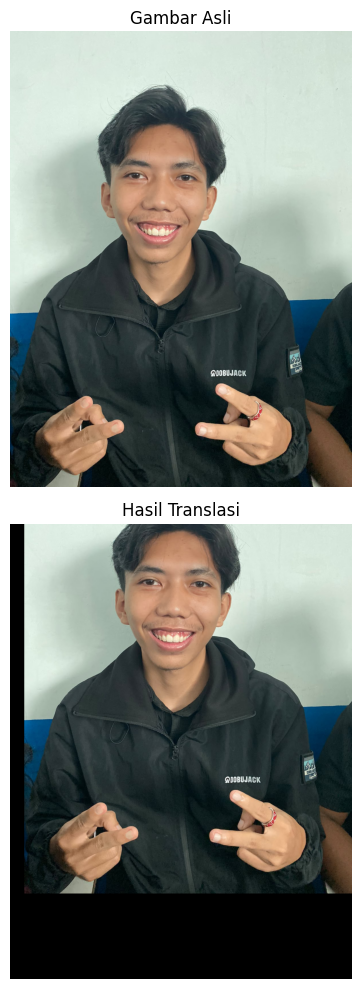

In [2]:
import imageio.v3 as img
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

def Translasi(image, shiftX, shiftY):
    imgTranslasi = np.roll(image, shift=shiftY, axis=0)
    imgTranslasi = np.roll(imgTranslasi, shift=shiftX, axis=1)

    if shiftY > 0:
        imgTranslasi[:shiftY, :] = 0
    elif shiftY < 0:
        imgTranslasi[shiftY:, :] = 0
    if shiftX > 0:
        imgTranslasi[:, :shiftX] = 0
    elif shiftX < 0:
        imgTranslasi[:, shiftX:] = 0

    return imgTranslasi

# Menampilkan tombol upload
uploaded = files.upload()

# Mengambil nama file pertama yang diunggah
file_name = next(iter(uploaded))

# Membaca gambar dari file yang diupload
image = img.imread(file_name)

# Proses translasi
imgResult = Translasi(image, shiftX=50, shiftY=-300)

# Menampilkan hasil
plt.figure(figsize=(10, 10))
plt.subplot(2, 1, 1)
plt.title("Gambar Asli")
plt.imshow(image)
plt.axis("off")

plt.subplot(2, 1, 2)
plt.title("Hasil Translasi")
plt.imshow(imgResult)
plt.axis("off")

plt.tight_layout()
plt.show()

Saving WhatsApp Image 2026-10-29 at 08.28.25.jpeg to WhatsApp Image 2026-10-29 at 08.28.25 (1).jpeg


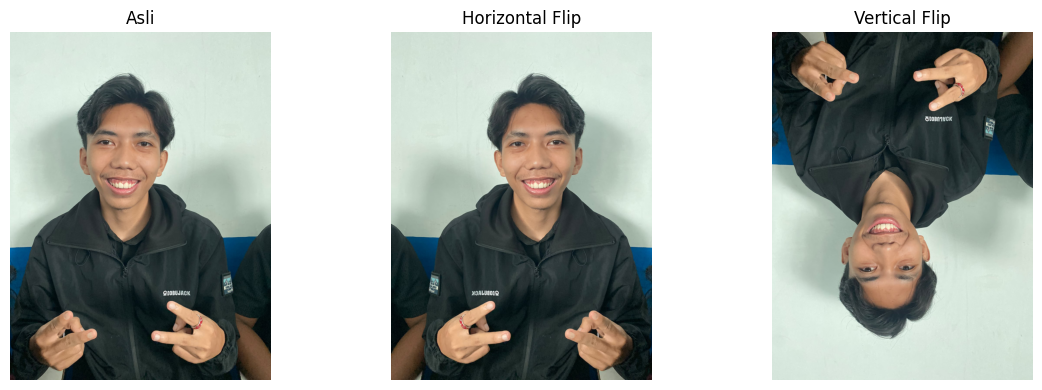

In [4]:
  import numpy as np
  import imageio.v3 as img
  import matplotlib.pyplot as plt
  from google.colab import files

  # 1. Upload file foto langsung dari komputermu
  uploaded = files.upload()

  # 2. Ambil nama file yang baru saja diunggah
  file_name = next(iter(uploaded))
  image = img.imread(file_name)

  # 3. Proses Flip Horizontal & Vertikal
  height, width = image.shape[:2]
  horizontal = np.zeros_like(image)
  vertical = np.zeros_like(image)

  for y in range(height):
      for x in range(width):
          horizontal[y, x] = image[y, width - 1 - x]

  for y in range(height):
      for x in range(width):
          vertical[y, x] = image[height - 1 - y, x]

  # 4. Tampilkan Gambar
  plt.figure(figsize=(12, 4))

  plt.subplot(1, 3, 1)
  plt.title("Asli")
  plt.imshow(image)
  plt.axis("off")

  plt.subplot(1, 3, 2)
  plt.title("Horizontal Flip")
  plt.imshow(horizontal)
  plt.axis("off")

  plt.subplot(1, 3, 3)
  plt.title("Vertical Flip")
  plt.imshow(vertical)
  plt.axis("off")

  plt.tight_layout()
  plt.show()

Saving WhatsApp Image 2026-10-29 at 08.28.25.jpeg to WhatsApp Image 2026-10-29 at 08.28.25 (2).jpeg


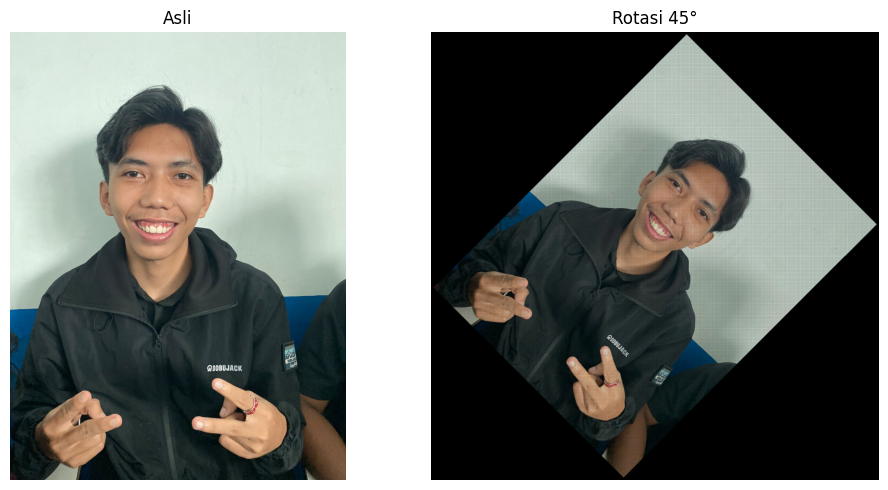

In [6]:
import numpy as np
import imageio.v3 as img
import matplotlib.pyplot as plt
from google.colab import files

def rotateImage(image, degree):
    radian_deg = np.radians(degree)
    cos_deg, sin_deg = np.cos(radian_deg), np.sin(radian_deg)

    height, width = image.shape[:2]
    max_dim = int(np.sqrt(height**2 + width**2))

    channels = image.shape[2] if image.ndim == 3 else 1
    if channels > 1:
        outputImage = np.zeros((max_dim, max_dim, channels), dtype=image.dtype)
    else:
        outputImage = np.zeros((max_dim, max_dim), dtype=image.dtype)

    centerY, centerX = max_dim // 2, max_dim // 2

    for y in range(-height // 2, height // 2):
        for x in range(-width // 2, width // 2):
            newX = int(cos_deg * x - sin_deg * y) + centerX
            newY = int(sin_deg * x + cos_deg * y) + centerY

            if 0 <= newX < max_dim and 0 <= newY < max_dim:
                outputImage[newY, newX] = image[y + height // 2, x + width // 2]
    return outputImage

# 1. Muncul tombol upload file
uploaded = files.upload()

# 2. Baca file yang baru diunggah
file_name = next(iter(uploaded))
image = img.imread(file_name)

# 3. Jalankan rotasi
rotated_image = rotateImage(image, 45)

# 4. Tampilkan gambar
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.title("Asli")
plt.imshow(image)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.title("Rotasi 45°")
plt.imshow(rotated_image)
plt.axis("off")

plt.tight_layout()
plt.show()

Saving WhatsApp Image 2026-10-29 at 08.28.25.jpeg to WhatsApp Image 2026-10-29 at 08.28.25 (7).jpeg


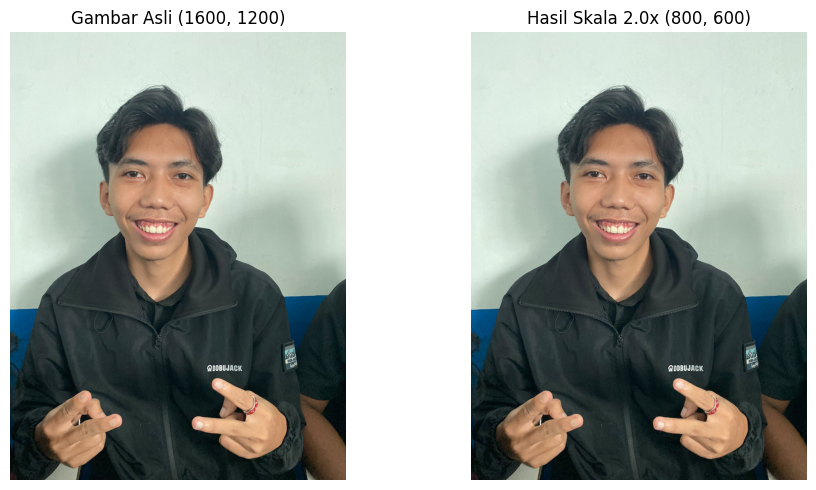

In [12]:
import numpy as np
import imageio.v3 as img
import matplotlib.pyplot as plt
from google.colab import files

def zoomPlus(image, factor):
    height, width = image.shape[:2]
    new_height = int(height / factor)
    new_width = int(width / factor)

    # Deteksi channel (RGB atau Grayscale)
    channels = image.shape[2] if image.ndim == 3 else 1
    if channels > 1:
        imgZoom = np.zeros((new_height, new_width, channels), dtype=image.dtype)
    else:
        imgZoom = np.zeros((new_height, new_width), dtype=image.dtype)

    for y in range(new_height):
        for x in range(new_width):
            ori_y = int(y * factor)
            ori_x = int(x * factor)

            ori_y = min(ori_y, height - 1)
            ori_x = min(ori_x, width - 1)

            imgZoom[y, x] = image[ori_y, ori_x]

    return imgZoom

# 1. Upload gambar dari komputer
uploaded = files.upload()
file_name = next(iter(uploaded))
image = img.imread(file_name)

# 2. Skala pengecilan/pembesaran
skala = 2.0
imgZoom = zoomPlus(image, skala)

# Simpan hasil secara lokal di runtime Colab
img.imwrite("hasil_zoom.jpg", imgZoom)

# 3. Tampilkan perbandingan
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.title(f"Gambar Asli {image.shape[:2]}")
plt.imshow(image)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.title(f"Hasil Skala {skala}x {imgZoom.shape[:2]}")
plt.imshow(imgZoom)
plt.axis("off")

plt.tight_layout()
plt.show()